# Milestone 2: Data wrangling
## Predicting low-carbon hours for data-center computing (PJM)

**Canvas project group:** 100
**Members:** Allen Garcia, Amy Chen, Clara Cheng, Luke Tan, Sunny Li

This notebook gets, loads and cleans the data, then states the revised project question.

1. Getting the data
2. Understanding the data
3. Cleaning and preprocessing
4. Project question

Exploratory analysis and the baseline models are Milestone 3. A first look at patterns is in `eda.ipynb`.

## 0. Setup

Run this cell first. On your own computer it does nothing. In Google Colab it gets the project files from Google Drive (default) or GitHub. The README section "Running in Google Colab" has the details.

In [1]:
import os, sys, subprocess
from pathlib import Path

SOURCE = "drive"   # "drive" or "github" (only used in Colab)
DRIVE_PATH = "/content/drive/MyDrive/AC209a-Carbon-Intensity/luke"  # the folder with this notebook
REPO = "lukektan917/AC209a-Carbon-Intensity"
SUBDIR = "luke"   # this notebook's folder inside the repo

if "google.colab" in sys.modules:
    if SOURCE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir(DRIVE_PATH)
    else:
        from google.colab import userdata
        local = Path("/content") / REPO.split("/")[1]
        if not local.exists():
            token = userdata.get("GITHUB_TOKEN")
            subprocess.run(["git", "clone", "--depth", "1",
                            f"https://{token}@github.com/{REPO}.git", str(local)], check=True)
            # Don't leave the token in the clone's config
            subprocess.run(["git", "-C", str(local), "remote", "set-url", "origin",
                            f"https://github.com/{REPO}.git"], check=True)
        os.chdir(local / SUBDIR)
    if not Path("data/pjm_hourly.csv").exists():
        subprocess.run([sys.executable, "build_dataset.py"], check=True)

print("Working in", os.getcwd())

Working in /Users/luketan/python/109/project/luke


In [2]:
import subprocess
import requests
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

pd.set_option("display.max_columns", 60, "display.width", 160, "display.max_colwidth", 120)

# Chart style (colorblind-checked palette, shared with eda.ipynb)
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SLOTS),
})

## 1. Getting the data

All sources are public and need no account or API key.

| Source | What we take from it | Files |
|---|---|---|
| [EIA-930 Hourly Electric Grid Monitor](https://www.eia.gov/electricity/gridmonitor/about), six-month bulk files | Hourly demand, EIA's day-ahead demand forecast, net generation, generation by fuel, and power flows with each neighboring grid, for PJM and its 7 neighbors | `EIA930_BALANCE_<year>_<half>.csv`, `EIA930_INTERCHANGE_<year>_<half>.csv` |
| [EIA CO₂ emissions coefficients](https://www.eia.gov/environment/emissions/co2_vol_mass.php) | kg CO₂ per MMBtu of coal, natural gas and oil | Hard-coded in `emission_factors.py` (3 numbers) |
| [EIA Electric Power Annual, Table 8.1](https://www.eia.gov/electricity/annual/html/epa_08_01.html) | Average heat rate (Btu of fuel per kWh of electricity) by fuel and year | Hard-coded in `emission_factors.py` |
| [NOAA GHCNh](https://www.ncei.noaa.gov/products/global-historical-climatology-network-hourly) (hourly weather) | Temperature, dew point and wind speed at 6 airports in PJM's load centers: Philadelphia, Chicago O'Hare, Washington Dulles, Baltimore, Pittsburgh, Columbus | `GHCNh_<station>_<year>.psv` |

**PJM** is the grid operator for 13 Mid-Atlantic and Midwest states plus Washington, D.C. It includes Northern Virginia, the largest data-center market in the world.

The period is 1 Jan 2019 to the most recent data, 11 Nov 2026.

### 1.1 Size of the source data

The EIA files cover every grid operator in the U.S., so they are much larger than what we keep. The cell below asks each server for each file's size, without downloading the files.

In [3]:
EIA_BASE = "https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/"
NOAA_BASE = "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/"
STATIONS = ["USW00013739", "USW00094846", "USW00093738", "USW00093721", "USW00094823", "USW00014821"]

meta = pd.read_csv(EIA_BASE + "EIA930_File_List_Meta.csv")
meta = meta[meta["DESCRIPTION"].isin(["BALANCE", "INTERCHANGE"]) & (meta["YEAR"].astype(int) >= 2019)]
eia_urls = [EIA_BASE + f for f in meta["FILENAME"]]
noaa_urls = [f"{NOAA_BASE}{y}/psv/GHCNh_{s}_{y}.psv" for y in range(2019, 2027) for s in STATIONS]

def size_bytes(url):
    r = requests.head(url, allow_redirects=True, timeout=60)
    r.raise_for_status()
    return int(r.headers["Content-Length"])

with ThreadPoolExecutor(8) as pool:
    eia_bytes = sum(pool.map(size_bytes, eia_urls))
    noaa_bytes = sum(pool.map(size_bytes, noaa_urls))

sizes = pd.DataFrame({
    "files": [len(eia_urls), len(noaa_urls)],
    "size (GB)": [eia_bytes / 1e9, noaa_bytes / 1e9],
}, index=["EIA-930 (balance + interchange)", "NOAA GHCNh (6 stations x 8 years)"])
sizes.loc["Total raw download"] = sizes.sum()
display(sizes.round(2))

final = Path("data/pjm_hourly.csv")
print(f"After keeping only PJM (and its neighbors' fuel mix): data/interim/ cache "
      f"{sum(f.stat().st_size for f in Path('data/interim').glob('*.parquet')) / 1e6:.0f} MB, "
      f"final table {final.stat().st_size / 1e6:.0f} MB")

,files,size (GB)
EIA-930 (balance + interchange),32.0,2.33
NOAA GHCNh (6 stations x 8 years),48.0,0.73
Total raw download,80.0,3.05


After keeping only PJM (and its neighbors' fuel mix): data/interim/ cache 27 MB, final table 35 MB


### 1.2 What a raw EIA file looks like

Each EIA-930 balance file has one row per grid operator per hour, about 65 text columns, and numbers written with thousands separators. Reading just the first rows of one file:

In [4]:
raw = pd.read_csv(EIA_BASE + "EIA930_BALANCE_2025_Jul_Dec.csv", nrows=3, dtype=str)
print(raw.shape[1], "columns. First rows:")
raw.iloc[:, :9]

65 columns. First rows:


,Balancing Authority,Data Date,Hour Number,Local Time at End of Hour,UTC Time at End of Hour,Demand Forecast (MW),Demand (MW),Net Generation (MW),Total Interchange (MW)
0,AECI,07/01/2025,1,07/01/2025 1:00:00 AM,07/01/2025 6:00:00 AM,2049,2082,3041,959
1,AECI,07/01/2025,2,07/01/2025 2:00:00 AM,07/01/2025 7:00:00 AM,1909,1966,2812,846
2,AECI,07/01/2025,3,07/01/2025 3:00:00 AM,07/01/2025 8:00:00 AM,1843,1852,2609,757


Two things in the raw files matter for cleaning:

- Most quantities appear up to three times: as reported, `(Imputed)` (EIA filled a gap) and `(Adjusted)` (EIA corrected it). We use the adjusted value when there is one and the reported value otherwise.
- From July 2024, EIA split hydro, solar and wind into sub-categories, such as "Solar with/without Integrated Battery Storage", and added storage and geothermal. Two of the new column names contain typos (`Pumped Storage  (Adjusted)` with a double space, `Solar witho Integrated …`). The build script fixes the names and sums the sub-categories back together, so the fuel columns mean the same thing in every year.

### 1.3 Download and build the table

`build_dataset.py` does the whole pipeline:

1. Download each six-month EIA file.
2. Keep only PJM's and its neighbors' rows, and cache them in `data/interim/`.
3. Delete the large raw file.
4. Download the NOAA files.
5. Join everything on the UTC hour.

The first run downloads about 3 GB and takes 10–20 minutes. Later runs read the cache and take under a minute. The cell only rebuilds if the table is missing, or if you set `REBUILD = True`.

In [5]:
REBUILD = False

if REBUILD or not Path("data/pjm_hourly.csv").exists():
    subprocess.run([sys.executable, "build_dataset.py"], check=True)
else:
    print("data/pjm_hourly.csv already built. Set REBUILD = True to download again.")

data/pjm_hourly.csv already built. Set REBUILD = True to download again.


### 1.4 From fuel mix to carbon intensity (units)

Our response variable is carbon intensity: kg of CO₂ emitted per MWh of electricity generated in PJM. EIA-930 has no emissions, so we calculate it.

The TA asked us to check units. EIA's CO₂ coefficients are per unit of **fuel** burned (kg CO₂ per MMBtu), but EIA-930 reports **electricity** generated (MW over one hour = MWh). The heat rate converts between them. It is the Btu of fuel a plant burns to make one kWh of electricity.

$$\frac{\text{kg CO}_2}{\text{MWh}} = \frac{\text{kg CO}_2}{\text{MMBtu}} \times \frac{\text{Btu}}{\text{kWh}} \times \frac{1}{1000}$$

Units check: (kg / 10⁶ Btu) × (Btu / kWh) = kg / 10⁶ kWh = kg / 1,000 MWh, so dividing by 1,000 gives kg/MWh.

Then, for each hour:

$$\text{CI}_t = \frac{\sum_f \text{gen}_{f,t} \times \text{EF}_{f,\text{year}}}{\sum_f \text{gen}_{f,t}}$$

The sums run over fuels *f*. Nuclear, hydro, wind, solar and storage have no direct emissions (EF = 0).

In [6]:
from emission_factors import CO2_KG_PER_MMBTU, factor_table

ef = factor_table(range(2019, 2027)).set_index("year")[["coal", "gas", "oil"]]
print("kg CO2 per MMBtu of fuel:", CO2_KG_PER_MMBTU)
print("\nkg CO2 per MWh of electricity, after multiplying by each year's heat rate (2026 reuses 2025):")
ef.round(0).astype(int)

kg CO2 per MMBtu of fuel: {'coal': 95.99, 'gas': 52.91, 'oil': 74.14}

kg CO2 per MWh of electricity, after multiplying by each year's heat rate (2026 reuses 2025):


,coal,gas,oil
year,,,
2019,1013,409,831
2020,1023,409,835
2021,1016,407,832
2022,1026,410,828
2023,1031,409,850
2024,1034,410,830
2025,1022,412,813
2026,1022,412,813


**Imports and exports (the TA's second point).** PJM trades power with 7 neighboring grids, so "PJM's emissions" can mean two things:

- **Production-based (our target, `ci_prod_kg_per_mwh`):** emissions from plants inside PJM, divided by their generation. Power flows across the border are ignored.
- **Consumption-based (sensitivity check, `ci_cons_kg_per_mwh`):** power PJM keeps (generation minus exports) is counted at PJM's intensity. Imports from each neighbor are counted at that neighbor's own intensity, which we calculate the same way from its EIA-930 fuel mix.

PJM is a net exporter, and in the median hour imports are only about 2% of its demand. The two versions are almost the same (section 2.4), so the production-based target is a safe choice. We will report the final scheduling result under both.

## 2. Understanding the data

### 2.1 Load the table

**One row is one hour of the PJM grid.** The timestamp `datetime_utc` marks the *end* of the hour, which is EIA's convention. For example, `2025-07-01 05:00 UTC` is the hour from midnight to 1 am Eastern Daylight Time.

In [7]:
df = pd.read_csv("data/pjm_hourly.csv", parse_dates=["datetime_utc"])
df["datetime_local"] = df["datetime_utc"].dt.tz_convert("America/New_York")
df["date_local"] = pd.to_datetime(df["date_local"])
CI = "ci_prod_kg_per_mwh"

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Hours: {df.datetime_utc.min()} to {df.datetime_utc.max()} (UTC, end of hour)")
print(f"Duplicate hours: {df.datetime_utc.duplicated().sum()}, "
      f"gaps in the hourly index: {(df.datetime_utc.diff().dropna() != pd.Timedelta('1h')).sum()}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

Shape: 68,904 rows x 52 columns
Hours: 2019-01-01 06:00:00+00:00 to 2026-11-11 05:00:00+00:00 (UTC, end of hour)
Duplicate hours: 0, gaps in the hourly index: 0
Memory: 25 MB


In [8]:
# One example row, shown as a column
df.iloc[[50_000]].T.rename(columns={50_000: "example hour"})

,example hour
datetime_utc,2024-09-14 14:00:00+00:00
datetime_local,2024-09-14 10:00:00-04:00
date_local,2024-09-14 00:00:00
hour_local,9
dow,5
month,9
demand_mw,84834.0
demand_forecast_mw,87836.0
net_gen_mw,89999.0
total_interchange_mw,5169.0


### 2.2 What each column means

The table has 52 columns in seven groups. The last column of the dictionary says whether a value is known by midnight the day before. That decides whether it can be a same-day feature for a day-ahead forecast (section 3.6).

In [9]:
neighbors = ["CPLE", "CPLW", "DUK", "LGEE", "MISO", "NYIS", "TVA"]
fuels = ["coal", "gas", "nuclear", "oil", "hydro", "solar", "wind", "storage", "other", "unknown"]
D = {  # column: (group, meaning, unit, known the day before?)
    "datetime_utc": ("Time", "End of the hour, UTC (EIA convention)", "", "yes"),
    "datetime_local": ("Time", "End of the hour, US Eastern", "", "yes"),
    "date_local": ("Time", "Eastern date the hour starts in", "", "yes"),
    "hour_local": ("Time", "Eastern hour the interval starts (0 = midnight to 1 am)", "0-23", "yes"),
    "dow": ("Time", "Day of week (0 = Monday)", "0-6", "yes"),
    "month": ("Time", "Month", "1-12", "yes"),
    "demand_mw": ("Grid", "Electricity used in PJM", "MW", "no, lag it"),
    "demand_forecast_mw": ("Grid", "EIA's day-ahead forecast of demand", "MW", "yes"),
    "net_gen_mw": ("Grid", "Total electricity generated in PJM (reported total)", "MW", "no, lag it"),
    "total_interchange_mw": ("Grid", "Net flow out of PJM (> 0 = net export)", "MW", "no, lag it"),
    "fuel_sum_mw": ("Grid", "Sum of the gen_<fuel> columns (negatives set to 0)", "MW", "no, lag it"),
    "co2_t": ("Emissions", "CO2 emitted by PJM plants this hour", "metric tons", "no (target-derived)"),
    "ci_prod_kg_per_mwh": ("Emissions", "TARGET: production-based carbon intensity", "kg CO2/MWh", "no (target)"),
    "ci_cons_kg_per_mwh": ("Emissions", "Import-adjusted carbon intensity (sensitivity check)", "kg CO2/MWh", "no (target)"),
    "imports_mw": ("Interchange", "Sum of flows into PJM from neighbors", "MW", "no, lag it"),
    "exports_mw": ("Interchange", "Sum of flows from PJM to neighbors", "MW", "no, lag it"),
    "temp_c": ("Weather", "Observed temperature, mean of 6 airports", "deg C", "no, lag it"),
    "dewpoint_c": ("Weather", "Observed dew point, mean of 6 airports", "deg C", "no, lag it"),
    "wind_ms": ("Weather", "Observed wind speed, mean of 6 airports", "m/s", "no, lag it"),
    "n_weather_stations": ("Weather", "Airports reporting this hour", "0-6", "n/a (QA)"),
    "eia_imputed": ("Quality", "EIA filled at least one value this hour", "bool", "n/a (QA)"),
    "qa_missing_hour": ("Quality", "No EIA data for this hour", "bool", "n/a (QA)"),
    "qa_fuel_mix_repeated": ("Quality", "Fuel mix is an exact copy of 24 h earlier (EIA gap-fill); target blanked", "bool", "n/a (QA)"),
    "qa_neighbor_ci_filled": ("Quality", "A neighbor's intensity was missing; PJM's used for its imports", "bool", "n/a (QA)"),
    "qa_fuel_sum_mismatch": ("Quality", "Fuel breakdown differs from net generation by > 5%", "bool", "n/a (QA)"),
    "qa_balance_mismatch": ("Quality", "Demand differs from generation - interchange by > 2%", "bool", "n/a (QA)"),
    "info_interchange_mismatch": ("Quality", "Total interchange disagrees with sum of per-neighbor flows (EIA's own gap; not in qa_any)", "bool", "n/a (QA)"),
    "qa_any": ("Quality", "Any qa_ flag", "bool", "n/a (QA)"),
}
for f in fuels:
    D[f"gen_{f}_mw"] = ("Generation", f"Generation from {f}", "MW", "no, lag it")
for n in neighbors:
    D[f"ic_{n}_mw"] = ("Interchange", f"Flow between PJM and {n} (> 0 = PJM exports)", "MW", "no, lag it")
    D[f"ci_{n}_kg_per_mwh"] = ("Interchange", f"{n}'s own production-based intensity", "kg CO2/MWh", "no, lag it")

assert set(D) == set(df.columns), set(df.columns) ^ set(D)
dictionary = pd.DataFrame(D, index=["group", "meaning", "unit", "known day before?"]).T
dictionary.insert(0, "dtype", df.dtypes.astype(str))
dictionary.index.name = "column"
dictionary

,dtype,group,meaning,unit,known day before?
column,,,,,
datetime_utc,"datetime64[ns, UTC]",Time,"End of the hour, UTC (EIA convention)",,yes
datetime_local,"datetime64[ns, America/New_York]",Time,"End of the hour, US Eastern",,yes
date_local,datetime64[ns],Time,Eastern date the hour starts in,,yes
hour_local,int64,Time,Eastern hour the interval starts (0 = midnight to 1 am),0-23,yes
dow,int64,Time,Day of week (0 = Monday),0-6,yes
month,int64,Time,Month,1-12,yes
demand_mw,float64,Grid,Electricity used in PJM,MW,"no, lag it"
demand_forecast_mw,float64,Grid,EIA's day-ahead forecast of demand,MW,yes
net_gen_mw,float64,Grid,Total electricity generated in PJM (reported total),MW,"no, lag it"


Neighbor codes: CPLE and CPLW are Duke Energy Progress East and West, DUK is Duke Energy Carolinas, LGEE is LG&E and KU, MISO is the Midcontinent ISO, NYIS is the New York ISO, and TVA is the Tennessee Valley Authority.

In [10]:
print("Data types:")
df.dtypes.astype(str).value_counts()

Data types:


float64                             38
bool                                 8
int64                                3
datetime64[ns, UTC]                  1
datetime64[ns, America/New_York]     1
datetime64[ns]                       1
Name: count, dtype: int64

### 2.3 Summary statistics

These are the mean, minimum and maximum of every numerical column, before cleaning. Values that look wrong are handled in section 3.3.

In [11]:
num = df.select_dtypes("number")
stats = num.describe().T[["count", "mean", "std", "min", "50%", "max"]]
stats.insert(1, "missing %", (num.isna().mean() * 100).round(2))
stats.round(1)

,count,missing %,mean,std,min,50%,max
hour_local,68904.0,0.0,11.5,6.9,0.0,11.5,23.0
dow,68904.0,0.0,3.0,2.0,0.0,3.0,6.0
month,68904.0,0.0,6.4,3.4,1.0,6.0,12.0
demand_mw,68900.0,0.0,92400.5,16052.3,56260.0,89587.5,224345.0
demand_forecast_mw,68641.0,0.4,91290.4,16405.6,56859.0,88545.0,165557.0
net_gen_mw,68900.0,0.0,96061.8,16333.2,63178.0,93102.0,164403.0
total_interchange_mw,68690.0,0.3,3511.0,2225.2,-4456.0,3483.0,14985.0
fuel_sum_mw,68900.0,0.0,95684.2,16488.0,287.0,92712.5,164281.0
gen_coal_mw,68895.0,0.0,17602.2,6736.4,5736.0,16184.0,44915.0
gen_gas_mw,68900.0,0.0,38648.4,9821.8,21.0,37306.0,75926.0


### 2.4 The response variable

The response variable is `ci_prod_kg_per_mwh`. It is continuous, so this is a regression problem.

The test period, 2024 onward, has a lower and narrower distribution than the training years. Section 3.4 shows the same shift.

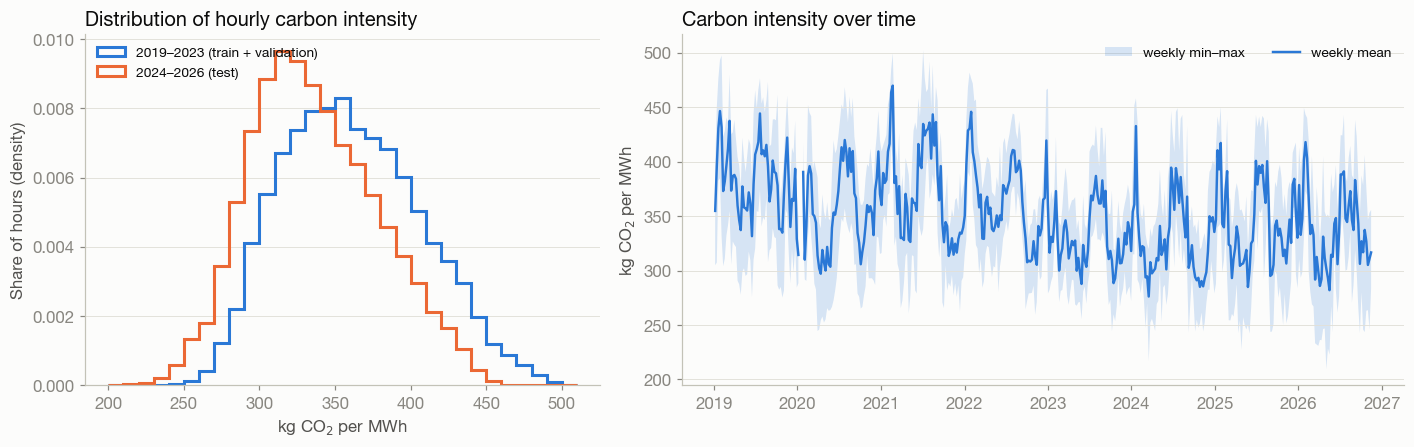

       mean   std    min    max
year                           
2019  382.7  41.7  275.2  497.4
2020  355.5  44.5  244.5  468.5
2021  372.9  48.1  260.6  502.2
2022  364.2  40.3  259.5  481.8
2023  329.7  31.4  244.2  433.2
2024  328.6  39.8  216.8  458.2
2025  343.2  41.9  227.4  450.6
2026  337.6  43.1  209.4  449.3


In [12]:
df["year"] = df["date_local"].dt.year
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
bins = np.arange(200, 520, 10)
ax.hist(df.loc[df.year <= 2023, CI].dropna(), bins=bins, density=True, histtype="step", lw=2, color=SLOTS[0], label="2019–2023 (train + validation)")
ax.hist(df.loc[df.year >= 2024, CI].dropna(), bins=bins, density=True, histtype="step", lw=2, color=SLOTS[1], label="2024–2026 (test)")
ax.set(title="Distribution of hourly carbon intensity", xlabel="kg CO$_2$ per MWh", ylabel="Share of hours (density)")
ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
weekly = df.set_index("datetime_local")[CI].resample("W").agg(["mean", "min", "max"])
ax.fill_between(weekly.index, weekly["min"], weekly["max"], color=SLOTS[0], alpha=0.18, lw=0, label="weekly min–max")
ax.plot(weekly.index, weekly["mean"], color=SLOTS[0], lw=1.6, label="weekly mean")
ax.set(title="Carbon intensity over time", ylabel="kg CO$_2$ per MWh")
ax.legend(loc="upper right", fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

print(df.groupby("year")[CI].agg(["mean", "std", "min", "max"]).round(1))

In [13]:
# Production- vs consumption-based intensity (TA's interchange question)
both = df[[CI, "ci_cons_kg_per_mwh"]].dropna()
diff = both["ci_cons_kg_per_mwh"] - both[CI]
print(f"Correlation: {both.corr().iloc[0, 1]:.3f}")
print(f"Consumption - production: mean {diff.mean():+.1f}, 5th-95th percentile {diff.quantile(.05):+.1f} to {diff.quantile(.95):+.1f} kg/MWh")
print(f"Imports as a share of demand: {(df.imports_mw / df.demand_mw).median():.1%} (median hour)")

Correlation: 0.997
Consumption - production: mean +0.2, 5th-95th percentile -3.8 to +6.4 kg/MWh
Imports as a share of demand: 2.1% (median hour)


## 3. Cleaning and preprocessing

### 3.1 Steps done while building the table

These happen in `build_dataset.py`, because they need the raw files.

| Step | Why |
|---|---|
| Keep only PJM's rows, plus its 7 neighbors' fuel mix | The raw files cover about 70 grid operators. We need the neighbors' fuel mix only for the import-adjusted intensity |
| Use EIA's `(Adjusted)` value when present, else the reported value | EIA corrects obvious reporting errors in the adjusted columns |
| Parse numbers written with thousands separators ("1,234") | Otherwise they would load as text |
| Fix the two misspelled column names, and sum the July 2024+ sub-categories back to hydro, solar and wind | Keeps fuel columns consistent across years. Before this fix, intensity after July 2024 was too high, because solar and wind were dropped |
| Set negative generation to 0 when computing intensity | Negative values are pumped-storage pumping or battery charging: consumption, not generation |
| Reindex to a complete hourly UTC index; drop EIA's empty placeholder rows at the end | Every hour gets exactly one row. UTC avoids the 23- and 25-hour days at daylight-saving changes |
| Blank the target when the fuel breakdown is outside 85–115% of reported net generation (compared before negatives are clipped, since net generation is net of pumped-storage pumping) | A fuel is missing or double-reported. Examples: 1 Oct 2022 reports 300 MW by fuel against 75 GW in total; 11 Feb 2022 is missing half of nuclear; 30 Sep 2022 reports 46 GW of nuclear, above PJM's capacity. The normal gap is about ±3% |
| Blank the target when the whole fuel mix is an exact copy of 24 hours earlier | EIA fills some gaps by copying the previous day, on every daylight-saving day and for 2–8 Jun 2026. A copy is not a measurement, and it would make the "same hour yesterday" baseline look perfect |
| Weather: drop observations that fail NOAA's quality codes or are physically impossible; round to the nearest hour; average the 6 airports; keep one value per station-hour | Removes bad readings. A reading just before New Year's midnight rounds into the next year's file, so it was being counted twice |
| Add Eastern-time calendar columns based on the hour's *start* | People and schedules think in local time; `hour_local = 0` means midnight to 1 am |

Sections 3.2–3.6 go through the checklist from the assignment.

### 3.2 Missing data

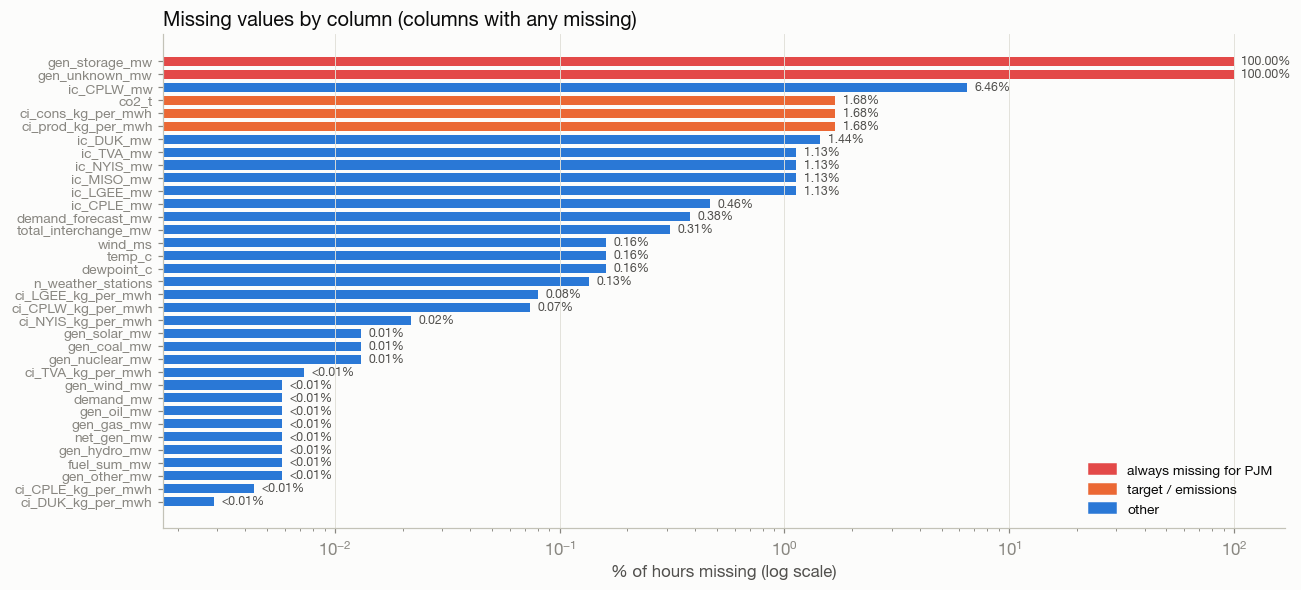

17 of 52 columns have no missing values.


In [14]:
miss = (df.drop(columns="year").isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(12, 5.5))
colors = [SLOTS[7] if v == 100 else SLOTS[1] if c in (CI, "ci_cons_kg_per_mwh", "co2_t") else SLOTS[0] for c, v in miss.items()]
ax.barh(miss.index[::-1], miss.values[::-1], color=colors[::-1], height=0.7)
ax.set_xscale("log")
ax.set(title="Missing values by column (columns with any missing)", xlabel="% of hours missing (log scale)")
ax.grid(axis="x", color=GRID, lw=0.6); ax.grid(axis="y", visible=False)
for y, (c, v) in enumerate(list(miss.items())[::-1]):
    ax.text(v * 1.08, y, f"{v:.2f}%" if v >= 0.01 else "<0.01%", va="center", fontsize=8, color=INK2)
ax.tick_params(axis="y", labelsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SLOTS[7], label="always missing for PJM"), Patch(color=SLOTS[1], label="target / emissions"),
                   Patch(color=SLOTS[0], label="other")], loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()
print(f"{len(df.columns) - 1 - len(miss)} of {len(df.columns) - 1} columns have no missing values.")

In [15]:
# Is missingness concentrated in time? Count of missing hours per year for the main columns.
key = [CI, "demand_mw", "demand_forecast_mw", "temp_c", "ic_CPLW_mw", "ic_MISO_mw"]
print("Missing hours by year")
display(df[key].isna().groupby(df.year).sum())

m = df.loc[df[CI].isna()]
why = pd.Series({
    "fuel breakdown outside 85-115% of net generation": ((m.fuel_sum_mw / m.net_gen_mw < 0.85) | (m.fuel_sum_mw / m.net_gen_mw > 1.15)).sum(),
    "fuel mix copied from previous day": m.qa_fuel_mix_repeated.sum(),
    "no fuel data at all": m.fuel_sum_mw.isna().sum(),
})
print(f"\nWhy the target is missing ({len(m):,} hours; an hour can have more than one reason):")
print(why.to_string())
print("\nMonths with the most missing target hours:")
print(m.datetime_local.dt.strftime("%Y-%m").value_counts().head(6).to_string())

Missing hours by year


,ci_prod_kg_per_mwh,demand_mw,demand_forecast_mw,temp_c,ic_CPLW_mw,ic_MISO_mw
year,,,,,,
2019,0,0,47,0,25,25
2020,756,0,47,0,50,49
2021,2,0,0,0,457,457
2022,63,0,23,0,48,48
2023,36,1,25,0,49,49
2024,48,1,48,0,49,49
2025,26,1,25,6,1662,26
2026,228,1,48,105,2113,73



Why the target is missing (1,159 hours; an hour can have more than one reason):
fuel breakdown outside 85-115% of net generation    806
fuel mix copied from previous day                   372
no fuel data at all                                   4

Months with the most missing target hours:
datetime_local
2020-01    710
2026-06    179
2023-11     29
2025-11     24
2024-11     24
2026-11     24


**What we found:**

- **The target is missing for 1.7% of hours, and the gaps are not random.**
  - Most of them (710) are in **January 2020**. That month EIA's fuel breakdown covers only about 77% of total generation, so whole fuels are missing.
  - Another 372 are EIA's copied days: every daylight-saving change, and a full week in June 2026.
- **`gen_storage_mw` and `gen_unknown_mw` are 100% missing.** PJM never reports these categories.
- **Interchange with CPLW** is missing for 6.5% of hours, almost all in 2025–26. CPLW is a small neighbor, at most about 600 MW of flow.
- **Weather** is missing for 0.2% of hours. Most of these are in 2026, when NOAA's files are still being filled in.

**How we handle it:**

| Missing | Decision | Reason |
|---|---|---|
| Target (`ci_prod_kg_per_mwh`) | Drop the hour. Never impute the target | An interpolated target would reward models for learning the interpolation. Scoring a forecast against made-up "truth" is meaningless |
| January 2020 | Drop the whole month | 710 of 744 hours are missing. The rest of the month is suspect too |
| `gen_storage_mw`, `gen_unknown_mw` | Drop the columns | No information |
| Lagged features (demand, generation, weather), in Milestone 3 | Forward-fill gaps of up to 3 hours, then drop rows that are still missing | Gaps are short and rare, and forward-fill uses only past values, so it doesn't leak |
| Neighbor flows and neighbor intensity | Keep as is | Used only for the import-adjusted sensitivity check. Missing neighbor intensity is already replaced by PJM's and flagged (`qa_neighbor_ci_filled`) |

### 3.3 Unusual values

We checked each numerical column against physical limits, and the target for sudden jumps.

In [16]:
checks = {
    "demand > 175 GW (record peak is about 165 GW)": df.demand_mw > 175_000,
    "demand < 50 GW": df.demand_mw < 50_000,
    "nuclear > 36 GW (PJM nuclear capacity is about 33 GW)": df.gen_nuclear_mw > 36_000,
    "any fuel < 0 MW (before clipping)": (df[[f"gen_{f}_mw" for f in fuels]] < 0).any(axis=1),
    "temperature outside -30..45 C": ~df.temp_c.between(-30, 45) & df.temp_c.notna(),
    "dew point above temperature": df.dewpoint_c > df.temp_c + 0.5,
    "neighbor intensity exactly 0": (df[[f"ci_{n}_kg_per_mwh" for n in neighbors]] == 0).any(axis=1),
}
print(pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="hours").to_string())

demand > 175 GW (record peak is about 165 GW)             4
demand < 50 GW                                            0
nuclear > 36 GW (PJM nuclear capacity is about 33 GW)    24
any fuel < 0 MW (before clipping)                         0
temperature outside -30..45 C                             0
dew point above temperature                               0
neighbor intensity exactly 0                             34


In [17]:
print("The 4 demand outliers:")
display(df.loc[checks["demand > 175 GW (record peak is about 165 GW)"],
               ["datetime_local", "demand_mw", "demand_forecast_mw", "net_gen_mw", "total_interchange_mw"]])

# Target: robust z-score within a rolling week, and hour-to-hour jumps
s = df.set_index("datetime_utc")[CI]
med = s.rolling("7D", center=True).median()
mad = (s - med).abs().rolling("7D", center=True).median()
z = (s - med) / (1.4826 * mad)
jump = s.diff().abs()
print(f"Target hours with |robust z| > 5 in their week: {(z.abs() > 5).sum()}")
print(f"Hour-to-hour changes > 60 kg/MWh: {(jump > 60).sum()} (99th percentile change: {jump.quantile(.99):.0f} kg/MWh)")
print(f"Target range: {s.min():.0f} to {s.max():.0f} kg/MWh. Both ends are plausible: "
      f"all-gas-and-nuclear spring nights vs. coal-heavy winter peaks.")

The 4 demand outliers:


,datetime_local,demand_mw,demand_forecast_mw,net_gen_mw,total_interchange_mw
11158,2020-04-10 00:00:00-04:00,215682.0,68940.0,70429.0,2840.0
13433,2020-07-13 19:00:00-04:00,224345.0,118248.0,128798.0,6200.0
13787,2020-07-28 13:00:00-04:00,192229.0,136862.0,140956.0,5392.0
13815,2020-07-29 17:00:00-04:00,176085.0,144563.0,147277.0,5919.0


Target hours with |robust z| > 5 in their week: 0
Hour-to-hour changes > 60 kg/MWh: 74 (99th percentile change: 34 kg/MWh)
Target range: 209 to 502 kg/MWh. Both ends are plausible: all-gas-and-nuclear spring nights vs. coal-heavy winter peaks.


In [18]:
# Direction of interchange by year: PJM should be a net exporter
net = df.groupby("year").apply(lambda g: (g.exports_mw - g.imports_mw).sum() / g.demand_mw.sum() * 100, include_groups=False)
print("Net exports as % of demand, by year (per-neighbor flows):")
print(net.round(1).to_string())

Net exports as % of demand, by year (per-neighbor flows):
year
2019   -4.6
2020    8.3
2021    6.8
2022    5.4
2023    6.7
2024    5.0
2025    3.5
2026    1.8


**What we found, and what we do:**

| Unusual value | Error or real? | Decision |
|---|---|---|
| 4 hours of demand at 176–224 GW (2020) | **Error.** Net generation those hours is 70–147 GW, and EIA's own forecast is normal | Set demand to missing. It is a feature, not the target |
| Fuel breakdown outside 85–115% of net generation, including 24 hours of impossible 46 GW nuclear | **Error** (missing or double-reported fuels) | Target already blanked in the build |
| Fuel mix identical to 24 h earlier (372 hours) | **Not a measurement** (EIA's gap-fill) | Target already blanked in the build |
| Neighbor intensity exactly 0 (CPLW, NYIS; 34 hours) | **Error** (partial report) | Leave. Only affects the import-adjusted check, and imports from those two are small |
| 2019 per-neighbor flows show PJM as a net importer; every later year is a net exporter | **Likely a reporting error** in 2019 interchange | Leave 2019 out of the import-adjusted sensitivity check |
| 74 hour-to-hour jumps > 60 kg/MWh in the target; no robust-z outliers | **Real.** They line up with fast gas and coal ramps | Keep |
| Gas output as low as 11 GW on some 2019–2020 nights | **Real.** Low-demand nights before PJM's gas build-out | Keep |

No negative fuel values remain after clipping, and no weather values are outside physical limits.

### 3.4 Class imbalance

The response variable is continuous, so there are no classes. The closest thing is the decision the scheduler makes: **which hour of the day is cleanest**. Treated as a 24-class label, that label is very unbalanced, and the dominant class flips between the training and test years:

In [19]:
daily = df.dropna(subset=[CI]).groupby("date_local").filter(lambda g: len(g) >= 23)
best = daily.loc[daily.groupby("date_local")[CI].idxmin(), ["date_local", "hour_local"]]
best["period"] = np.where(best.date_local.dt.year <= 2023, "2019–2023", "2024–2026")
best["block"] = pd.cut(best.hour_local, [-1, 5, 9, 15, 19, 23],
                       labels=["night 0–5", "morning 6–9", "midday 10–15", "afternoon 16–19", "evening 20–23"])
share = pd.crosstab(best.block, best.period, normalize="columns").mul(100).round(1)
print("Share of days whose cleanest hour falls in each block (%)")
share

Share of days whose cleanest hour falls in each block (%)


period,2019–2023,2024–2026
block,,
night 0–5,65.6,22.9
morning 6–9,7.0,16.6
midday 10–15,12.2,52.8
afternoon 16–19,3.2,4.3
evening 20–23,12.0,3.5


In 2019–2023, the cleanest hour was usually at night. From 2024 it is usually midday, as solar grew. A model trained mostly on older years would learn the wrong default. This affects Milestone 3 in two ways:

- **Splits:** we split by time and validate on the most recent pre-test year (2023), never with a random split.
- **Metrics:** besides MAE and RMSE, we score how good the hour each model *chooses* is (scheduling regret), because a good average error does not guarantee the right hour is picked.

### 3.5 Scale of the features

In [20]:
feat = ["hour_local", "dow", "month", "demand_mw", "demand_forecast_mw", "net_gen_mw", "total_interchange_mw",
        "gen_coal_mw", "gen_gas_mw", "gen_nuclear_mw", "gen_oil_mw", "gen_hydro_mw", "gen_solar_mw", "gen_wind_mw",
        "gen_other_mw", "imports_mw", "exports_mw", "temp_c", "dewpoint_c", "wind_ms", CI]
rng = df[feat].agg(["min", "max", "std"]).T
rng["range"] = rng["max"] - rng["min"]
rng["unit"] = [D[c][2] for c in feat]
rng.round(1)

,min,max,std,range,unit
hour_local,0.0,23.0,6.9,23.0,0-23
dow,0.0,6.0,2.0,6.0,0-6
month,1.0,12.0,3.4,11.0,1-12
demand_mw,56260.0,224345.0,16052.3,168085.0,MW
demand_forecast_mw,56859.0,165557.0,16405.6,108698.0,MW
net_gen_mw,63178.0,164403.0,16333.2,101225.0,MW
total_interchange_mw,-4456.0,14985.0,2225.2,19441.0,MW
gen_coal_mw,5736.0,44915.0,6736.4,39179.0,MW
gen_gas_mw,21.0,75926.0,9821.8,75905.0,MW
gen_nuclear_mw,16001.0,46004.0,2161.6,30003.0,MW


The features differ in scale by about five orders of magnitude: wind speed varies by about 13 m/s, while demand varies by more than 100,000 MW. For regularized linear regression and k-nearest neighbors, we will standardize every feature, using means and standard deviations from the **training years only** so that no test-period information leaks in. Tree models such as random forests and gradient boosting don't need scaling.

Hour of day and month are circular: hour 23 is next to hour 0. For linear models we will encode them as sine and cosine pairs.

### 3.6 Information leakage

We forecast tomorrow's 24 hourly values at midnight Eastern time tonight. Anything recorded during tomorrow is not known then. Each column's status is in the dictionary in section 2.2:

| Can use directly | Use only lagged by ≥ 24 hours | Never a feature |
|---|---|---|
| Calendar columns (`hour_local`, `dow`, `month`, holidays) and `demand_forecast_mw`, which EIA publishes the day before | Demand, net generation, every `gen_<fuel>_mw`, interchange, neighbor intensity, observed weather, and past values of the target | `co2_t`, `ci_cons_kg_per_mwh` (both computed from the target) and the `qa_*` flags (computed after the fact) |

Three subtler leaks to avoid in Milestone 3:

- **Observed weather.** Same-day observed temperature is not a forecast. We have no archive of day-ahead weather forecasts. So weather enters only lagged, and any run with same-day weather is labeled an "oracle" upper bound.
- **Fitting on all years.** Scalers, imputations and any target encodings are fit on the training years only.
- **Data release lag.** We assume today's EIA data is available at midnight. In practice EIA posts it with a short delay, so lag-24 features are slightly optimistic. We will test lag 48 as a robustness check.

### 3.7 Apply the decisions: the cleaned modeling table

In [21]:
clean = df.copy()

# 1. Feature outliers -> missing
clean.loc[clean.demand_mw > 175_000, "demand_mw"] = np.nan

# 2. Columns with no information for PJM
clean = clean.drop(columns=["gen_storage_mw", "gen_unknown_mw"])

# 3. Rows: drop January 2020, and every hour whose target is missing
jan2020 = (clean.date_local >= "2020-01-01") & (clean.date_local < "2020-02-01")
clean = clean.loc[~jan2020 & clean[CI].notna()].copy()

# 4. Time-based split labels (used from Milestone 3 on)
clean["split"] = pd.cut(clean.date_local, [pd.Timestamp("2000-01-01"), pd.Timestamp("2023-01-01"),
                                           pd.Timestamp("2024-01-01"), pd.Timestamp("2100-01-01")],
                        labels=["train", "validation", "test"], right=False).astype(str)
clean = clean.drop(columns=["year"])

clean.to_parquet("data/pjm_clean.parquet", index=False)
print(f"Before cleaning: {df.shape[0]:,} rows x {df.shape[1] - 1} columns")
print(f"After cleaning:  {clean.shape[0]:,} rows x {clean.shape[1]} columns  -> data/pjm_clean.parquet")
print(f"Rows removed: {df.shape[0] - clean.shape[0]:,} ({(df.shape[0] - clean.shape[0]) / df.shape[0]:.1%})")
clean.groupby("split").agg(hours=(CI, "size"), first=("date_local", "min"), last=("date_local", "max"),
                           mean_ci=(CI, "mean")).loc[["train", "validation", "test"]].round(1)

Before cleaning: 68,904 rows x 52 columns
After cleaning:  67,712 rows x 51 columns  -> data/pjm_clean.parquet
Rows removed: 1,192 (1.7%)


,hours,first,last,mean_ci
split,,,,
train,34210,2019-01-01,2022-12-31,369.2
validation,8724,2023-01-01,2023-12-31,329.7
test,24778,2024-01-01,2026-11-10,336.4


## 4. Project question

### Revised question

> **Using only information available at midnight the day before, can a model forecast each hour of PJM's carbon intensity well enough that scheduling a flexible data-center job into the forecast's cleanest hours cuts its CO₂ more than simple rules do?**

The question can be answered at the end of the project. On the test period (1 Jan 2024 onward, never used for fitting or model selection), the model must beat two benchmarks:

1. **Forecast accuracy:** lower MAE than persistence, which predicts each hour as the same hour yesterday. Persistence's MAE is computed below.
2. **Scheduling:** a job placed using the model's forecast must get a larger share of the best possible CO₂ saving than placing it at yesterday's cleanest hour. Both are measured against a random start hour, and the best possible saving comes from perfect foresight. We report this for a 1-hour job and a 4-hour job that must run within the day.

If the model beats both benchmarks, the answer is yes. If it beats persistence on MAE but not on scheduling, the answer is "more accurate but not more useful", which is also a result. Both outcomes are reported under the production-based and the import-adjusted intensity.

In [22]:
# The two benchmarks, on the test period (computed here only to make the question measurable)
t = clean.set_index("datetime_utc")[[CI, "date_local", "hour_local", "split"]]
full = t.reindex(pd.date_range(t.index.min(), t.index.max(), freq="h", tz="UTC"))
full["persist"] = full[CI].shift(24)
test = full[full.split == "test"].dropna(subset=[CI, "persist"])
print(f"Benchmark 1 - persistence MAE on test: {(test[CI] - test.persist).abs().mean():.1f} kg/MWh "
      f"({(test[CI] - test.persist).abs().mean() / test[CI].mean():.1%} of the mean)")

days = clean[clean.split == "test"].groupby("date_local").filter(lambda g: len(g) == 24)
piv = days.pivot_table(index="date_local", columns="hour_local", values=CI)
random_start = piv.mean(axis=1)
oracle = piv.min(axis=1)
# "Yesterday" means the previous calendar day, so reindex to every date before shifting
prev = piv.reindex(pd.date_range(piv.index.min(), piv.index.max(), freq="D")).shift(1).loc[piv.index]
prev = prev.dropna()
yday_best = prev.idxmin(axis=1)
ok = piv.index.isin(yday_best.index)
rule = pd.Series([piv.loc[d, h] for d, h in yday_best.items()], index=yday_best.index)
share = (random_start[ok] - rule).sum() / (random_start[ok] - oracle[ok]).sum()
print(f"Benchmark 2 - 'yesterday's cleanest hour' captures {share:.0%} of the perfect-foresight saving "
      f"for a 1-hour job ({ok.sum()} complete test days)")

Benchmark 1 - persistence MAE on test: 16.7 kg/MWh (5.0% of the mean)
Benchmark 2 - 'yesterday's cleanest hour' captures 61% of the perfect-foresight saving for a 1-hour job (1007 complete test days)


### How the question changed from the proposal, and why

The core question is the same. What changed is how it is measured, based on what the data showed:

| Original proposal | Revised | What in the data changed it |
|---|---|---|
| Compare the schedule with "running the workload immediately" | Compare with a random start hour, and with the rule "run at yesterday's cleanest hour" | "Immediately" depends on when a job is submitted. A simple rule already gets a large share of the possible saving, so beating "immediately" would be too easy (section 4 benchmarks) |
| MAE and RMSE | MAE and RMSE, plus scheduling regret and share of the perfect-foresight saving | The decision only needs the ranking of hours, and the cleanest-hour label is unbalanced and shifting (section 3.4) |
| Weather "if it improves the model" | Lagged weather only; same-day weather only as a labeled oracle | We only have observed weather, which is not known a day ahead (section 3.6) |
| Time-based split (years unspecified) | Train 2019–2022 (without January 2020), validate 2023, test 2024 onward | January 2020 is unusable (section 3.2), and the cleanest hour moved from night to midday (section 3.4) |
| Emission factors from EIA (units not discussed) | Fuel-based factors converted with yearly heat rates; production-based target with an import-adjusted check | Staff conditions on units and interchange (section 1.4) |

**Staff notes on the approval, and where each is met:**

1. *Units of emission factors vs. generation.* EIA's factors are per MMBtu of fuel. We convert them to kg CO₂ per MWh of electricity with EIA's yearly heat rates (section 1.4).
2. *Interchange between areas.* The target is production-based. An import-adjusted version counts imports at each neighbor's own intensity (section 1.4). The two correlate at about 0.997 (section 2.4), and we will report results under both.